# Supplementary notebook: Quantitative certification of quantum imaginarity in prepare-and-measure scenarios

Companion code to the article *Quantitative certification of quantum imaginarity in prepare-and-measure scenarios* by Sudip Chakrabarty (S. N. Bose National Centre for Basic Sciences, Kolkata). The notebook is self-contained: it needs only Python 3 with `numpy`, `scipy`, `sympy` and `matplotlib`, and it saves the four figures of the paper as PDF files in a folder `figs/`. A LaTeX installation with `txfonts` is used for the figure fonts when available; otherwise the notebook falls back to matplotlib's built-in Times-like fonts.

This notebook reproduces every computation behind the manuscript, in the order of the paper.

1. Setting and notation for the three-to-one qubit code, and the quantifier $V$.
2. Real and complex optima of the three-to-one code.
3. Symbolic verification of every algebraic step in the proof of Theorem 1.
4. Numerical stress tests of Theorem 1 and Proposition 1.
5. The preparation quantifier $W$ and Theorem 2.
6. Robustness: white noise, leakage, Table 1.
7. Figures 1 to 3.
8. Two-to-one codes in dimension $d$ (Hadamard criterion, Table 3).
9. Qutrits: the real optimum $7/9$ and general real measurements.
10. The Jarlskog invariant, the circulant family and Conjecture 1.
11. The $n$-to-one qubit family (Table 4, asymptotics).
12. Certification from published data (Section 8).
13. Figure 4.

**Status of the results.** Theorems 1 to 4, Propositions 1 to 8 and Corollaries 1 and 2 are proven analytically in the paper; the notebook only verifies their algebra and stress-tests them. The following are numerical results obtained by local optimisation with random restarts, which are lower bounds on the true optima and are not claimed to be global: the orange curve of Fig. 2(b), the qutrit leakage search of Sec. 6, the real values of Table 3 for $d\neq3$, the real optimum over general (non-projective) real qutrit measurements, the values of Table 4 for $n\ge4$, and the evidence for Conjecture 1.

Random seeds are fixed. The whole notebook runs in about 10 to 20 minutes on a laptop (the first cell prints the package versions used).

Additional cells at the end check the operational bound of Section 3.3 (exposing complex conjugation), compute Table 2 (rounds needed for certification), the adversarial certificate for the published data, document the failure of the symmetrization route to Conjecture 1, and compute the detection-efficiency threshold of Proposition 3.

In [1]:
import sys, numpy, scipy, sympy, matplotlib
print("python", sys.version.split()[0], "| numpy", numpy.__version__, "| scipy", scipy.__version__,
      "| sympy", sympy.__version__, "| matplotlib", matplotlib.__version__)

python 3.13.18 | numpy 2.5.3 | scipy 1.18.1 | sympy 1.14.0 | matplotlib 3.11.2


In [2]:
import itertools, time, os
os.makedirs("figs", exist_ok=True)
import numpy as np
import sympy as sp
from scipy.optimize import minimize
import matplotlib
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

# All eight inputs x = (x1, x2, x3) and the signs (-1)^{x_y}
X = np.array(list(itertools.product([0, 1], repeat=3)))
SG = (-1.0) ** X                      # shape (8, 3)
SIGNS4 = np.array([(1, 1, 1), (1, 1, -1), (1, -1, 1), (1, -1, -1)], float)

P_C = 0.75                                    # classical bit
P_R = 0.5 + (1 + np.sqrt(5)) / 12             # real qubit (rebit)
P_Q = 0.5 + np.sqrt(3) / 6                    # complex qubit

def Pbound(V):
    # Theorem 1: maximal success probability at measurement imaginarity V
    V = np.asarray(V, float)
    return 0.5 + np.sqrt(6 + 2 * np.sqrt(5 + 4 * V**2)) / 12

def Vcert(P):
    # Inverse of Pbound: certified lower bound on V from an observed success probability P
    P = np.asarray(P, float)
    s = 12 * P - 6
    z = ((s**2 - 6) / 2) ** 2 - 5
    return np.where(P <= P_R, 0.0, 0.5 * np.sqrt(np.clip(z, 0, None)))

def Vbar_cert(P):
    # Shared randomness: chord of the convex curve Pbound
    return np.clip((np.asarray(P) - P_R) / (P_Q - P_R), 0, None)

print(f"P_C = {P_C:.6f},  P_R = {P_R:.6f},  P_Q = {P_Q:.6f},  P_Q - P_R = {P_Q-P_R:.6f}")

P_C = 0.750000,  P_R = 0.769672,  P_Q = 0.788675,  P_Q - P_R = 0.019003


## 1. Success probability in Bloch form

A qubit strategy consists of states $\rho_x=\tfrac12(\mathbb 1+\mathbf r_x\cdot\boldsymbol\sigma)$ and binary observables $A_y=c_y\mathbb{1}+\mathbf n_y\cdot\boldsymbol\sigma$ with $|c_y|+|\mathbf n_y|\le 1$. The success probability is
$P=\tfrac12+\tfrac1{48}\sum_x \mathbf r_x\cdot\mathbf N_x$ with $\mathbf N_x=\sum_y(-1)^{x_y}\mathbf n_y$, so the optimal states give $P=\tfrac12+\tfrac1{24}\sum_{k=1}^4|\mathbf N_k|$.
The function below evaluates $P$ directly from density matrices and effects, and the cell checks it against the Bloch formula.

In [3]:
sx = np.array([[0, 1], [1, 0]], complex); sy = np.array([[0, -1j], [1j, 0]]); sz = np.diag([1., -1]).astype(complex)
PAULI = np.array([sx, sy, sz]); I2 = np.eye(2)

def rho_of(r):  return 0.5 * (I2 + np.einsum('i,ijk->jk', r, PAULI))
def A_of(c, n): return c * I2 + np.einsum('i,ijk->jk', n, PAULI)

def success(rhos, As):
    # P = (1/24) sum_{x,y} Tr[rho_x E_{x_y|y}],  E_{b|y} = (1 + (-1)^b A_y)/2
    P = 0.0
    for k, x in enumerate(X):
        for y in range(3):
            E = 0.5 * (I2 + (-1) ** x[y] * As[y])
            P += np.trace(rhos[k] @ E).real
    return P / 24

def V_of(n):  return abs(np.linalg.det(np.asarray(n)))
def S_of(n):  return np.linalg.norm(SIGNS4 @ np.asarray(n), axis=1).sum()

# check: random unsharp, biased measurements with optimal states
for _ in range(3):
    n = rng.normal(size=(3, 3)); n /= np.linalg.norm(n, axis=1)[:, None]; n *= rng.uniform(0.3, 1, (3, 1))
    c = np.array([rng.uniform(-(1 - np.linalg.norm(v)), 1 - np.linalg.norm(v)) for v in n])
    N = SG @ n; r = N / np.linalg.norm(N, axis=1, keepdims=True)
    P_direct = success([rho_of(v) for v in r], [A_of(c[y], n[y]) for y in range(3)])
    print(f"direct {P_direct:.12f}   Bloch formula {0.5 + S_of(n)/24:.12f}")

# V equals 4 |Im Tr(E1 E2 E3)| for the effects E_{0|y}
E0 = [0.5 * (I2 + A_of(c[y], n[y])) for y in range(3)]
print("V =", V_of(n), "  4|Im Tr(E1E2E3)| =", 4 * abs(np.trace(E0[0] @ E0[1] @ E0[2]).imag))

direct 0.736756998552   Bloch formula 0.736756998552
direct 0.650049284233   Bloch formula 0.650049284233
direct 0.674004248477   Bloch formula 0.674004248477
V = 0.1410387264942895   4|Im Tr(E1E2E3)| = 0.14103872649428945


## 2. Optimal real and complex values

The real optimum is attained by $\mathbf n_1\perp\mathbf n_2$ and $\mathbf n_3=-\mathbf n_2$, which gives $|\mathbf N_k|\in\{1,1,\sqrt5,\sqrt5\}$. We confirm by brute-force optimisation over coplanar measurement directions.

In [4]:
def S_planar(a):
    return S_of(np.stack([np.cos(a), np.sin(a), 0 * a], 1))

best = 0
for _ in range(500):
    r = minimize(lambda a: -S_planar(a), rng.uniform(0, 2*np.pi, 3), method='Nelder-Mead',
                 options={'xatol': 1e-12, 'fatol': 1e-14})
    best = max(best, -r.fun)
print("max over coplanar directions: P =", 0.5 + best/24, "   closed form P_R =", P_R)
print("orthonormal directions:       P =", 0.5 + S_of(np.eye(3))/24, "   closed form P_Q =", P_Q)
print("real optimum S = 2 + 2 sqrt5 :", S_of(np.array([[1,0,0],[0,1,0],[0,-1,0]])), 2 + 2*np.sqrt(5))

max over coplanar directions: P = 0.7696723314583158    closed form P_R = 0.7696723314583158
orthonormal directions:       P = 0.7886751345948129    closed form P_Q = 0.7886751345948129
real optimum S = 2 + 2 sqrt5 : 6.47213595499958 6.47213595499958


## 3. Symbolic verification of the proof of Theorem 1

Notation of the paper: $g_1=\mathbf n_1\cdot\mathbf n_2$, $g_2=\mathbf n_1\cdot\mathbf n_3$, $g_3=\mathbf n_2\cdot\mathbf n_3$ for unit vectors; $p_k=|\mathbf N_k|^2$; $A=3+2g_3$, $B=3-2g_3$, $\sigma=g_1+g_2$, $\tau=g_1-g_2$, $x=\sigma^2/A$, $y=\tau^2/B$, and $R=5+4V^2$.

In [5]:
g1, g2, g3 = sp.symbols('g1 g2 g3', real=True)
G = sp.Matrix([[1, g1, g2], [g1, 1, g3], [g2, g3, 1]])
V2 = sp.expand(G.det())                                     # V^2 = det(Gram matrix)
eps = [(1, 1, 1), (1, -1, -1), (-1, 1, -1), (-1, -1, 1)]     # (s1 s2, s1 s3, s2 s3) for N_1..N_4
p = [3 + 2*(e[0]*g1 + e[1]*g2 + e[2]*g3) for e in eps]

A = 3 + 2*g3; B = 3 - 2*g3; sig = g1 + g2; tau = g1 - g2
x = sig**2 / A; y = tau**2 / B; R = 5 + 4*V2

checks = {
  "p1+p4 = 2A":                      sp.simplify(p[0] + p[3] - 2*A),
  "p1-p4 = 4 sigma":                 sp.simplify(p[0] - p[3] - 4*sig),
  "p2+p3 = 2B":                      sp.simplify(p[1] + p[2] - 2*B),
  "p2-p3 = 4 tau":                   sp.simplify(p[1] - p[2] - 4*tau),
  "p1 p4 = A^2 - 4 sigma^2":         sp.simplify(p[0]*p[3] - (A**2 - 4*sig**2)),
  "(A-2s^2/A)^2-(A^2-4s^2)=4s^4/A^2": sp.simplify((A - 2*sig**2/A)**2 - (A**2 - 4*sig**2) - 4*sig**4/A**2),
  "R = AB-(B-1)Ax-(A-1)By":          sp.simplify(R - (A*B - (B-1)*A*x - (A-1)*B*y)),
  "(A-x)(B-y)-R = (AB-6)(x+y)+xy":   sp.simplify((A-x)*(B-y) - R - ((A*B-6)*(x+y) + x*y)),
  "AB - 6 = 3 - 4 g3^2":             sp.simplify(A*B - 6 - (3 - 4*g3**2)),
}
for k, v in checks.items():
    print(f"{k:38s} -> residual {v}")

# Lemma 2: (3-4u^2)^2 <= R  <=>  Q <= u^2 (5-4u^2), with Q = g1^2+g2^2-2 g1 g2 g3
Q = g1**2 + g2**2 - 2*g1*g2*g3
print("Lemma 2 reduction residual:", sp.simplify((R - (3 - 4*g3**2)**2) - 4*(g3**2*(5 - 4*g3**2) - Q)))
print("Q = 1 - g3^2 - V^2 residual:", sp.simplify(Q - (1 - g3**2 - V2)))
u = sp.symbols('u', positive=True)
print("case (i) threshold: root of 4u^2+2u-3 :", sp.nsolve(4*u**2 + 2*u - 3, u, 0.6), "=", sp.N((sp.sqrt(13)-1)/4))
print("case (ii) threshold: sqrt((3-sqrt5)/4) :", sp.N(sp.sqrt((3 - sp.sqrt(5))/4)), "=", sp.N((sp.sqrt(5)-1)/(2*sp.sqrt(2))))

p1+p4 = 2A                             -> residual 0
p1-p4 = 4 sigma                        -> residual 0
p2+p3 = 2B                             -> residual 0
p2-p3 = 4 tau                          -> residual 0
p1 p4 = A^2 - 4 sigma^2                -> residual 0
(A-2s^2/A)^2-(A^2-4s^2)=4s^4/A^2       -> residual 0
R = AB-(B-1)Ax-(A-1)By                 -> residual 0
(A-x)(B-y)-R = (AB-6)(x+y)+xy          -> residual 0
AB - 6 = 3 - 4 g3^2                    -> residual 0
Lemma 2 reduction residual: 0
Q = 1 - g3^2 - V^2 residual: 0
case (i) threshold: root of 4u^2+2u-3 : 0.651387818865997 = 0.651387818865997
case (ii) threshold: sqrt((3-sqrt5)/4) : 0.437016024448821 = 0.437016024448821


In [6]:
# Numerical sanity check of Lemma 2 on a dense grid of Gram matrices with |g3| maximal
t = np.linspace(-1, 1, 241)
G1, G2, G3 = np.meshgrid(t, t, t, indexing='ij')
D = 1 + 2*G1*G2*G3 - G1**2 - G2**2 - G3**2
mask = (D >= 0) & (np.abs(G3) >= np.abs(G1)) & (np.abs(G3) >= np.abs(G2))
margin = np.sqrt(5 + 4*np.clip(D, 0, None)) - (3 - 4*G3**2)
print("grid points:", mask.sum(), "  minimal margin of Lemma 2:", margin[mask].min())

grid points: 2864837   minimal margin of Lemma 2: 0.0


In [7]:
# Ingredients of Proposition 1 (unsharp measurements): convexity of S*(V) and its tangent intercept
Vs = sp.symbols('V', nonnegative=True)
Sstar = 2*sp.sqrt(6 + 2*sp.sqrt(5 + 4*Vs**2))
d2 = sp.lambdify(Vs, sp.diff(Sstar, Vs, 2))
icpt = sp.simplify(Sstar - Vs*sp.diff(Sstar, Vs))
grid = np.linspace(0, 1, 20001)
print("min S*''(V) on [0,1]          :", min(d2(v) for v in grid))
print("tangent intercept at V = 1     :", sp.nsimplify(sp.simplify(icpt.subs(Vs, 1))), "=", float(icpt.subs(Vs, 1)))
print("4 sqrt2                         :", 4*np.sqrt(2))

min S*''(V) on [0,1]          : 0.34213349285311156
tangent intercept at V = 1     : 32*sqrt(3)/9 = 6.158402871356008
4 sqrt2                         : 5.656854249492381


## 4. Numerical stress tests of Theorem 1

We test $S\le S^\star(V)=2\sqrt{6+2\sqrt{5+4V^2}}$ for random strategies and with a batched adversarial hill climb that allows unsharp measurements ($|\mathbf n_y|\le1$). We also evaluate the optimal family $\mathbf n_1=\hat z$, $\mathbf n_{2,3}=(\cos\tfrac\theta2,\pm\sin\tfrac\theta2,0)$ with $V=\sin\theta$.

In [8]:
Sstar_np = lambda V: 2*np.sqrt(6 + 2*np.sqrt(5 + 4*V**2))

def gap_batch(Nb):
    S = np.linalg.norm(np.einsum('sk,bkj->bsj', SIGNS4, Nb), axis=2).sum(1)
    return S - Sstar_np(np.abs(np.linalg.det(Nb)))

def project(Nb):
    L = np.linalg.norm(Nb, axis=2, keepdims=True); return Nb / np.maximum(L, 1)

t0 = time.time()
Bsz = 40000
Nb = project(rng.normal(size=(Bsz, 3, 3)) * 0.7)
g = gap_batch(Nb); step = 0.2
for it in range(2000):
    M = project(Nb + rng.normal(size=Nb.shape) * step)
    gm = gap_batch(M); acc = gm > g; Nb[acc] = M[acc]; g[acc] = gm[acc]
    if it % 400 == 399: step *= 0.5
i = g.argmax()
print(f"adversarial search: max (S - S*(V)) = {g.max():.2e}  at V = {abs(np.linalg.det(Nb[i])):.4f}  ({time.time()-t0:.0f} s)")

for th in [0.2, 0.7, 1.2, np.pi/2]:
    n = np.array([[0, 0, 1], [np.cos(th/2), np.sin(th/2), 0], [np.cos(th/2), -np.sin(th/2), 0]])
    print(f"family theta = {th:.3f}:  V = {V_of(n):.6f},  P = {0.5 + S_of(n)/24:.10f},  bound = {Pbound(V_of(n)):.10f}")

adversarial search: max (S - S*(V)) = 8.88e-16  at V = 1.0000  (69 s)
family theta = 0.200:  V = 0.198669,  P = 0.7705728546,  bound = 0.7705728546
family theta = 0.700:  V = 0.644218,  P = 0.7784059364,  bound = 0.7784059364
family theta = 1.200:  V = 0.932039,  P = 0.7865297351,  bound = 0.7865297351
family theta = 1.571:  V = 1.000000,  P = 0.7886751346,  bound = 0.7886751346


## 5. Imaginarity of the preparations

For given states, $\Delta_y=\tfrac18\sum_x(-1)^{x_y}\rho_x$ and the optimal measurement for bit $y$ is along the Bloch vector $\mathbf R_y=\sum_x(-1)^{x_y}\mathbf r_x$ of $\Delta_y$. The quantifier is $W=4|\mathrm{Im}\,\mathrm{Tr}(\Delta_1\Delta_2\Delta_3)|/(\|\Delta_1\|_1\|\Delta_2\|_1\|\Delta_3\|_1)=|\det(\hat{\mathbf R}_1,\hat{\mathbf R}_2,\hat{\mathbf R}_3)|$. Theorem 2 states $P\le\mathcal P(W)$. Below we check the identity for $W$, test the bound, and compute the numerically tight curve $\max\{P: W\le w\}$.

In [9]:
def W_and_P(r):
    R = SG.T @ r
    norms = np.linalg.norm(R, axis=1)
    W = abs(np.linalg.det(R / norms[:, None]))
    return W, 0.5 + norms.sum() / 48

# identity check with density matrices
r = rng.normal(size=(8, 3)); r /= np.linalg.norm(r, axis=1, keepdims=True); r *= rng.uniform(0.5, 1, (8, 1))
rhos = [rho_of(v) for v in r]
Dl = [sum((-1)**X[k, y] * rhos[k] for k in range(8)) / 8 for y in range(3)]
tn = [np.abs(np.linalg.eigvalsh(d)).sum() for d in Dl]
W_op = 4 * abs(np.trace(Dl[0] @ Dl[1] @ Dl[2]).imag) / np.prod(tn)
print("W from operators:", W_op, "   W from Bloch vectors:", W_and_P(r)[0])

worst = -1
for _ in range(100000):
    r = rng.normal(size=(8, 3)); r /= np.linalg.norm(r, axis=1, keepdims=True); r *= rng.uniform(0, 1, (8, 1))**0.1
    W, P = W_and_P(r); worst = max(worst, P - Pbound(W))
print("max (P - P(W)) over random preparations with optimal measurements:", worst)

W from operators: 0.08309405833397947    W from Bloch vectors: 0.08309405833397948


max (P - P(W)) over random preparations with optimal measurements: -0.03133723328123794


In [10]:
def detW(p):
    R = SG.T @ p.reshape(8, 3); return np.linalg.det(R / np.linalg.norm(R, axis=1, keepdims=True))

def tight_prep(w, restarts=30):
    best = None
    cons = [{'type': 'ineq', 'fun': lambda p: w - detW(p)}, {'type': 'ineq', 'fun': lambda p: w + detW(p)}] + \
           [{'type': 'ineq', 'fun': (lambda p, k=k: 1 - np.sum(p.reshape(8, 3)[k]**2))} for k in range(8)]
    for _ in range(restarts):
        r = minimize(lambda p: -np.linalg.norm(SG.T @ p.reshape(8, 3), axis=1).sum(), rng.normal(size=24),
                     constraints=cons, method='SLSQP', options={'maxiter': 2000, 'ftol': 1e-13})
        if r.success and abs(detW(r.x)) <= w + 1e-7 and (best is None or r.fun < best.fun):
            best = r
    return 0.5 - best.fun / 48

t0 = time.time()
W_grid = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98, 1.0])
P_tight = np.array([tight_prep(w) for w in W_grid])
for w, pt in zip(W_grid, P_tight):
    print(f"W <= {w:.2f}:  numerical max P = {pt:.6f},  Theorem 2 bound = {Pbound(w):.6f},  gap = {Pbound(w)-pt:.4f}")
print(f"({time.time()-t0:.0f} s)")

W <= 0.00:  numerical max P = 0.769672,  Theorem 2 bound = 0.769672,  gap = -0.0000
W <= 0.10:  numerical max P = 0.769776,  Theorem 2 bound = 0.769902,  gap = 0.0001
W <= 0.20:  numerical max P = 0.770090,  Theorem 2 bound = 0.770585,  gap = 0.0005
W <= 0.30:  numerical max P = 0.770630,  Theorem 2 bound = 0.771702,  gap = 0.0011
W <= 0.40:  numerical max P = 0.771420,  Theorem 2 bound = 0.773223,  gap = 0.0018
W <= 0.50:  numerical max P = 0.772502,  Theorem 2 bound = 0.775113,  gap = 0.0026
W <= 0.60:  numerical max P = 0.773946,  Theorem 2 bound = 0.777331,  gap = 0.0034
W <= 0.70:  numerical max P = 0.775865,  Theorem 2 bound = 0.779836,  gap = 0.0040
W <= 0.80:  numerical max P = 0.778471,  Theorem 2 bound = 0.782586,  gap = 0.0041
W <= 0.85:  numerical max P = 0.780154,  Theorem 2 bound = 0.784041,  gap = 0.0039
W <= 0.90:  numerical max P = 0.782222,  Theorem 2 bound = 0.785544,  gap = 0.0033
W <= 0.95:  numerical max P = 0.784883,  Theorem 2 bound = 0.787090,  gap = 0.0022
W <

## 6. Robustness

**White noise.** Depolarising the preparations with visibility $\eta$ gives $P=\tfrac12+\eta(P_Q-\tfrac12)$ for the ideal strategy.

**Almost qubits.** If every state has weight at least $1-\varepsilon$ on a fixed two-dimensional subspace, Proposition 4 gives $P\le\mathcal P(V')+\sqrt\varepsilon$, where $V'$ is the imaginarity of the effects compressed to that subspace. We also run a local optimisation over qutrit strategies to see how large $P-\mathcal P(V')$ can actually become. The values found there are lower bounds on the true penalty and are reported only as an indication.

In [11]:
eta_star = (P_R - 0.5) / (P_Q - 0.5)
eps_star = (P_Q - P_R)**2
print(f"visibility threshold eta* = {eta_star:.6f} = (1+sqrt5)/(2 sqrt3) = {(1+np.sqrt(5))/(2*np.sqrt(3)):.6f}")
print(f"leakage threshold eps*    = {eps_star:.4e}")

print("\nTable 1")
print(" eta    P         V_min    Vbar_min   eps_max")
for eta in [0.94, 0.95, 0.96, 0.97, 0.98, 0.99, 1.00]:
    P = 0.5 + eta * (P_Q - 0.5)
    print(f" {eta:.2f}  {P:.5f}   {float(Vcert(P)):.3f}    {float(Vbar_cert(P)):.3f}     {(P-P_R)**2:.2e}")

visibility threshold eta* = 0.934172 = (1+sqrt5)/(2 sqrt3) = 0.934172
leakage threshold eps*    = 3.6111e-04

Table 1
 eta    P         V_min    Vbar_min   eps_max
 0.94  0.77135   0.273    0.089     2.83e-06
 0.95  0.77424   0.456    0.240     2.09e-05
 0.96  0.77713   0.591    0.392     5.56e-05
 0.97  0.78001   0.707    0.544     1.07e-04
 0.98  0.78290   0.811    0.696     1.75e-04
 0.99  0.78579   0.908    0.848     2.60e-04
 1.00  0.78868   1.000    1.000     3.61e-04


In [12]:
def herm(v):
    M = (v[:9] + 1j*v[9:]).reshape(3, 3); return M + M.conj().T
PI = np.diag([1, 1, 0]).astype(complex)

def qutrit_strategy(par, eps):
    E = []
    for yy in range(3):
        H = herm(par[18*yy:18*yy+18]); w, U = np.linalg.eigh(H)
        d = 1 / (1 + np.exp(-par[54+3*yy:57+3*yy]))
        E.append(U @ np.diag(d) @ U.conj().T)
    q = par[63:].reshape(8, 6); P = 0.0
    for k, xx in enumerate(X):
        a = q[k, :2] + 1j*q[k, 2:4]; a = a / np.linalg.norm(a)
        th = np.arcsin(np.sqrt(eps)) * np.tanh(q[k, 5])**2
        psi = np.r_[np.cos(th)*a, np.sin(th)*np.exp(1j*q[k, 4])]
        for yy in range(3):
            e = (psi.conj() @ E[yy] @ psi).real
            P += e if xx[yy] == 0 else 1 - e
    Ec = [(PI @ e @ PI)[:2, :2] for e in E]
    return P/24, 4*abs(np.trace(Ec[0] @ Ec[1] @ Ec[2]).imag)

t0 = time.time()
for eps in [1e-4, 1e-3, 1e-2]:
    worst = -1
    for _ in range(8):
        f = lambda par: -(lambda PV: PV[0] - Pbound(PV[1]))(qutrit_strategy(par, eps))
        r = minimize(f, rng.normal(size=63+48), method='L-BFGS-B', options={'maxiter': 3000})
        worst = max(worst, -r.fun)
    print(f"eps = {eps:.0e}:  largest P - P(V') found = {worst:.2e}   (rigorous bound sqrt(eps) = {np.sqrt(eps):.2e})")
print(f"({time.time()-t0:.0f} s)")

eps = 1e-04:  largest P - P(V') found = 2.78e-05   (rigorous bound sqrt(eps) = 1.00e-02)


eps = 1e-03:  largest P - P(V') found = 5.40e-04   (rigorous bound sqrt(eps) = 3.16e-02)


eps = 1e-02:  largest P - P(V') found = 5.09e-03   (rigorous bound sqrt(eps) = 1.00e-01)
(53 s)


## 7. Figures

All figures use the fonts of the manuscript (Times via `txfonts`), sizes matching APS figures, bold distinguishable colours, grids, and legends outside the data region.

In [13]:
# Set USE_LATEX = False if no LaTeX installation with txfonts is available
# (for example, when MiKTeX would wait for a package-installation prompt).
import shutil
USE_LATEX = shutil.which("latex") is not None
matplotlib.rcParams.update({
    "text.usetex": USE_LATEX, "mathtext.fontset": "stix",
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{txfonts}",
    "font.family": "serif" if USE_LATEX else "STIXGeneral", "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "legend.fontsize": 7.5, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.7, "lines.linewidth": 1.6, "grid.linewidth": 0.4, "grid.alpha": 0.5,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
})
RED, BLUE, GREEN, PURPLE, ORANGE, GRAY, BLACK = "#D62728", "#1F4FBF", "#1A9E3A", "#8E3FBF", "#F07F00", "#9A9A9A", "#000000"

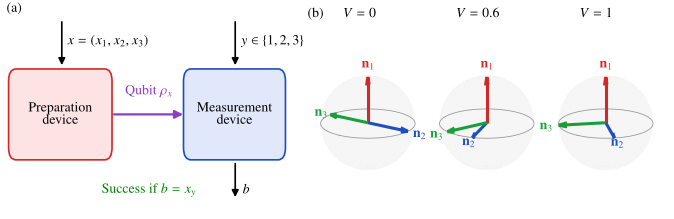

In [14]:
# Figure 1: (a) the game, (b) optimal measurement directions for three values of V
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from mpl_toolkits.mplot3d import Axes3D  # noqa

fig = plt.figure(figsize=(6.5, 2.15))
axA = fig.add_axes([0.0, 0.0, 0.46, 1.0]); axA.set_xlim(0, 10); axA.set_ylim(0, 4.4); axA.axis('off')
def box(ax, x, y, w, h, fc, ec, label):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08,rounding_size=0.25", fc=fc, ec=ec, lw=1.2))
    ax.text(x + w/2, y + h/2, label, ha='center', va='center', fontsize=10)
box(axA, 0.3, 1.25, 3.3, 1.7, "#FDE3E3", RED, r"Preparation" "\n" r"device")
box(axA, 6.15, 1.25, 3.25, 1.7, "#E1E8FB", BLUE, r"Measurement" "\n" r"device")
axA.add_patch(FancyArrowPatch((3.65, 2.1), (6.15, 2.1), arrowstyle='-|>', mutation_scale=12, lw=1.6, color=PURPLE))
axA.text(4.9, 2.45, r"Qubit $\rho_x$", ha='center', va='bottom', fontsize=10, color=PURPLE)
axA.add_patch(FancyArrowPatch((2.0, 4.05), (2.0, 3.05), arrowstyle='-|>', mutation_scale=10, lw=1.2, color=BLACK))
axA.text(2.2, 3.6, r"$x=(x_1,x_2,x_3)$", ha='left', va='center', fontsize=10)
axA.add_patch(FancyArrowPatch((7.8, 4.05), (7.8, 3.05), arrowstyle='-|>', mutation_scale=10, lw=1.2, color=BLACK))
axA.text(8.0, 3.6, r"$y\in\{1,2,3\}$", ha='left', va='center', fontsize=10)
axA.add_patch(FancyArrowPatch((7.8, 1.15), (7.8, 0.35), arrowstyle='-|>', mutation_scale=10, lw=1.2, color=BLACK))
axA.text(8.05, 0.55, r"$b$", ha='left', va='center', fontsize=10)
axA.text(4.9, 0.55, r"Success if $b=x_y$", ha='center', va='center', fontsize=10, color="green")
axA.text(0.15, 4.2, r"(a)", fontsize=10)

def sphere(ax):
    u = np.linspace(0, 2*np.pi, 60); v = np.linspace(0, np.pi, 30)
    ax.plot_surface(np.outer(np.cos(u), np.sin(v)), np.outer(np.sin(u), np.sin(v)), np.outer(np.ones_like(u), np.cos(v)),
                    color='#EDEDED', alpha=0.25, linewidth=0, shade=False)
    for ang in [0]:
        tt = np.linspace(0, 2*np.pi, 100)
        ax.plot(np.cos(tt), np.sin(tt), 0*tt, color=GRAY, lw=0.6)
    ax.set_xlim(-0.86, 0.86); ax.set_ylim(-0.86, 0.86); ax.set_zlim(-0.86, 0.86); ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=18, azim=35); ax.axis('off'); ax.set_facecolor('none')

for j, (th, lab) in enumerate([(np.pi, r"$V=0$"), (np.arcsin(0.6), r"$V=0.6$"), (np.pi/2, r"$V=1$")]):
    if th == np.pi:
        n = np.array([[0, 0, 1], [0, 1, 0], [0, -1, 0]])
    else:
        n = np.array([[0, 0, 1], [np.cos(th/2), np.sin(th/2), 0], [np.cos(th/2), -np.sin(th/2), 0]])
    ax = fig.add_axes([0.455 + 0.183*j, -0.06, 0.21, 0.98], projection='3d', computed_zorder=False); sphere(ax)
    for vec, col, nm in zip(n, [RED, BLUE, GREEN], [r"$\mathbf n_1$", r"$\mathbf n_2$", r"$\mathbf n_3$"]):
        ax.quiver(0, 0, 0, *vec, color=col, lw=2.2, arrow_length_ratio=0.18, zorder=10, alpha=1.0)
        ax.text(*(1.27*np.asarray(vec, float)), nm, color=col, fontsize=10, ha='center', va='center', zorder=11)
    fig.text(0.455 + 0.182*j + 0.095, 0.93, lab, ha='center', fontsize=10)
fig.text(0.47, 0.93, r"(b)", fontsize=10)
fig.savefig("figs/fig1.pdf"); plt.show()

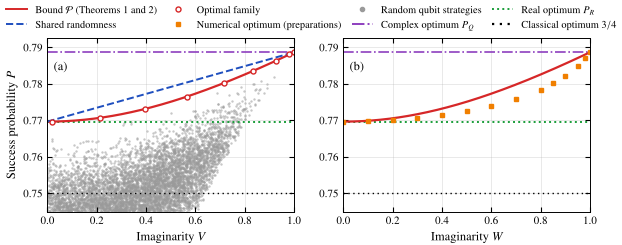

In [15]:
# Figure 2: (a) measurement tradeoff, (b) preparation tradeoff
Vg = np.linspace(0, 1, 400)
# random qubit strategies with optimal states (sharp and unsharp measurements)
nr = rng.normal(size=(60000, 3, 3)); nr /= np.linalg.norm(nr, axis=2, keepdims=True)
nr *= rng.uniform(0.8, 1.0, (60000, 3, 1))
Sr = np.linalg.norm(np.einsum('sk,bkj->bsj', SIGNS4, nr), axis=2).sum(1)
Vr = np.abs(np.linalg.det(nr)); Pr = 0.5 + Sr/24
fam_th = np.linspace(0.02, np.pi/2, 9)
fam_V = np.sin(fam_th)

#fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(3.375, 4.55), sharex=True, gridspec_kw={'hspace': 0.08})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 2.25), sharex=True, gridspec_kw={'hspace': 0.08})
for ax in (ax1, ax2):
    ax.axhline(P_Q, color=PURPLE, ls='-.', lw=1.2)
    ax.axhline(P_R, color=GREEN, ls=':', lw=1.4)
    ax.axhline(P_C, color=BLACK, ls=(0, (1, 2.5)), lw=1.0)
    ax.grid(True); ax.set_ylim(0.745, 0.7925); ax.set_xlim(0, 1)
sel = Pr > 0.745
ax1.scatter(Vr[sel][:6000], Pr[sel][:6000], s=3, color=GRAY, alpha=0.55, rasterized=True, lw=0, label=r"Random qubit strategies")
ax1.plot(Vg, Pbound(Vg), color=RED, label=r"Theorem 1")
ax1.plot(Vg, P_R + (P_Q - P_R)*Vg, color=BLUE, ls='--', lw=1.4, label=r"Shared randomness")
ax1.plot(fam_V, Pbound(fam_V), 'o', ms=3.6, mfc='white', mec=RED, mew=1.0, label=r"Optimal family")
ax1.set_xlabel(r"Imaginarity $V$")
ax1.set_ylabel(r"Success probability $P$")
ax1.text(0.025, 0.7838, r"(a)", fontsize=9)
ax2.plot(Vg, Pbound(Vg), color=RED, label=r"Theorem 2")
ax2.plot(W_grid, P_tight, 's', ms=3.4, color=ORANGE, label=r"Numerical optimum")
ax2.set_xlabel(r"Imaginarity $W$")
#ax2.set_ylabel(r"Success probability $P$")
ax2.text(0.025, 0.7838, r"(b)", fontsize=9)
# common legend above the plot, outside the axes
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=RED, lw=1.4, label=r"Bound $\mathcal{P}$ (Theorems 1 and 2)"),
           Line2D([], [], color=BLUE, ls='--', lw=1.4, label=r"Shared randomness"),
           Line2D([], [], marker='o', ls='', ms=3.6, mfc='none', mec=RED, label=r"Optimal family"),
           Line2D([], [], marker='s', ls='', ms=3.4, color=ORANGE, label=r"Numerical optimum (preparations)"),
           Line2D([], [], marker='o', ls='', ms=3, color=GRAY, label=r"Random qubit strategies"),
           Line2D([], [], color=PURPLE, ls='-.', lw=1.4, label=r"Complex optimum $P_Q$"),
           Line2D([], [], color=GREEN, ls=':', lw=1.4, label=r"Real optimum $P_R$"),
           Line2D([], [], color=BLACK, ls=(0, (1, 2.5)), lw=1.6, label=r"Classical optimum $3/4$")]
ax1.legend(handles=handles, loc='lower center', bbox_to_anchor=(1.07, 1.02), ncol=4, frameon=False,
           handlelength=2, columnspacing=1.0, borderaxespad=0.0)
fig.savefig("figs/fig2.pdf"); plt.show()

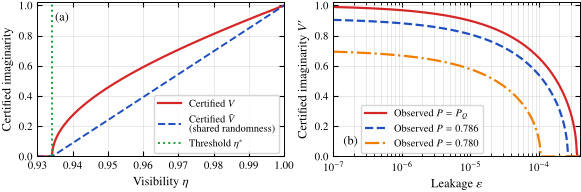

In [16]:
# Figure 3: (a) certified imaginarity versus visibility, (b) versus leakage
eta = np.linspace(0.93, 1.0, 400); Peta = 0.5 + eta*(P_Q - 0.5)
#fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(3.375, 4.1), gridspec_kw={'hspace': 0.62})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 2), gridspec_kw={'hspace': 0.62})
ax1.plot(eta, Vcert(Peta), color=RED, label=r"Certified $V$")
ax1.plot(eta, Vbar_cert(Peta), color=BLUE, ls='--', lw=1.4, label=r"Certified $\bar V$" "\n" r"(shared randomness)")
ax1.axvline(eta_star, color=GREEN, ls=':', lw=1.4, label=r"Threshold $\eta^\ast$")
ax1.set_xlabel(r"Visibility $\eta$"); ax1.set_ylabel(r"Certified imaginarity")
ax1.set_xlim(0.93, 1.0); ax1.set_ylim(0, 1.02); ax1.grid(True)
ax1.legend(loc='lower left', bbox_to_anchor=(0.45, -0.01), ncol=1, frameon=True, handlelength=2.2, columnspacing=1.0)
#ax1.text(0.997, 0.06, r"(a)", fontsize=9, ha='right')
ax1.text(0.935, 0.9, r"(a)", fontsize=9, ha='left')
epsg = np.logspace(-7, np.log10(4e-4), 400)
for Pobs, col, ls in [(P_Q, RED, '-'), (0.786, BLUE, '--'), (0.780, ORANGE, '-.')]:
    ax2.plot(epsg, Vcert(Pobs - np.sqrt(epsg)), color=col, ls=ls, label=rf"Observed $P={Pobs:.3f}$" if Pobs != P_Q else r"Observed $P=P_Q$")
ax2.set_xscale('log'); ax2.set_xlabel(r"Leakage $\varepsilon$"); ax2.set_ylabel(r"Certified imaginarity $V'$")
ax2.set_xlim(1e-7, 4e-4); ax2.set_ylim(0, 1.02); ax2.grid(True, which='both')
ax2.legend(loc='lower left', bbox_to_anchor=(0.09, -0.01), ncol=1, frameon=True, handlelength=2.0, columnspacing=0.8)
ax2.text(1.4e-7, 0.08, r"(b)", fontsize=9)
fig.savefig("figs/fig3.pdf"); plt.show()

## 8. Two-to-one codes in dimension $d$

For rank-one projective measurements onto bases with overlap matrix $U_{ij}=\langle a_i|b_j\rangle$, the largest eigenvalue of $|a_i\rangle\langle a_i|+|b_j\rangle\langle b_j|$ is $1+|U_{ij}|$, so $P=\tfrac12+\tfrac1{2d^2}\sum_{ij}|U_{ij}|$. We check the eigenvalue formula and compute the real optimum $\max_{O\in O(d)}\sum|O_{ij}|$ (Table 3).

In [17]:
from scipy.linalg import expm
from scipy.stats import unitary_group
rngq = np.random.default_rng(11)

# eigenvalue formula check
U = unitary_group.rvs(4, random_state=rngq)
a, b = np.eye(4)[:, 1], U[:, 2]
lam = np.linalg.eigvalsh(np.outer(a, a.conj()) + np.outer(b, b.conj()))[-1]
print("lambda_max =", lam, "   1+|<a|b>| =", 1 + abs(a.conj() @ b))

def O_of(h, d):
    K = np.zeros((d, d)); K[np.triu_indices(d, 1)] = h; return expm(K - K.T)

table2 = []
for d in range(2, 9):
    m = d*(d-1)//2; best = 0
    for _ in range(400 if d < 7 else 150):
        r = minimize(lambda h: -np.abs(O_of(h, d)).sum(), rngq.normal(size=m)*2, method='L-BFGS-B')
        best = max(best, -r.fun)
    PR, PQ = 0.5 + best/(2*d*d), 0.5 + 1/(2*np.sqrt(d))
    table2.append((d, best, PR, PQ))
    print(f"d={d}: Sigma_R={best:.6f}  d^1.5={d**1.5:.6f}  P_R={PR:.6f}  P_Q={PQ:.6f}  gap={PQ-PR:.2e}")

lambda_max = 1.2816645257996884    1+|<a|b>| = 1.2816645257996881


d=2: Sigma_R=2.828427  d^1.5=2.828427  P_R=0.853553  P_Q=0.853553  gap=-1.42e-14


d=3: Sigma_R=5.000000  d^1.5=5.196152  P_R=0.777778  P_Q=0.788675  gap=1.09e-02


d=4: Sigma_R=8.000000  d^1.5=8.000000  P_R=0.750000  P_Q=0.750000  gap=-2.00e-15


d=5: Sigma_R=11.000000  d^1.5=11.180340  P_R=0.720000  P_Q=0.723607  gap=3.61e-03


d=6: Sigma_R=14.324555  d^1.5=14.696938  P_R=0.698952  P_Q=0.704124  gap=5.17e-03


d=7: Sigma_R=17.970563  d^1.5=18.520259  P_R=0.683373  P_Q=0.688982  gap=5.61e-03


d=8: Sigma_R=22.627417  d^1.5=22.627417  P_R=0.676777  P_Q=0.676777  gap=3.50e-10


## 9. Qutrits: the real optimum $7/9$

Theorem 3 uses that every $3\times3$ sign matrix has $\det S\in\{0,\pm4\}$, and that $O_H=\mathbb 1-\tfrac23\mathbf 1\mathbf 1^T$ attains $\sum|O_{ij}|=5$. We check both, and then maximise the success probability over **general** real three-outcome measurements (Kraus parametrisation) to see whether non-projective real measurements could beat $7/9$.

In [18]:
dets = set(int(round(np.linalg.det(np.array(s).reshape(3, 3)))) for s in itertools.product([1, -1], repeat=9))
print("determinants of all 512 sign matrices:", sorted(dets))
OH = np.eye(3) - 2/3*np.ones((3, 3))
print("O_H orthogonal:", np.allclose(OH.T @ OH, np.eye(3)), "  sum|O_H| =", np.abs(OH).sum())
print("singular values of the sign matrix of O_H:", np.linalg.svd(np.sign(OH))[1])

def povm(K, cplx=False):
    M = sum(k @ k.conj().T for k in K); w, V = np.linalg.eigh(M)
    Mi = V @ np.diag(w**-0.5) @ V.conj().T
    return [Mi @ k @ k.conj().T @ Mi for k in K]

def P_general(p, cplx=False):
    if cplx:
        K1 = (p[:27] + 1j*p[27:54]).reshape(3, 3, 3); K2 = (p[54:81] + 1j*p[81:]).reshape(3, 3, 3)
    else:
        K1 = p[:27].reshape(3, 3, 3); K2 = p[27:].reshape(3, 3, 3)
    A, B = povm(K1), povm(K2)
    return sum(np.linalg.eigvalsh(a + b)[-1] for a in A for b in B) / 18

t0 = time.time(); best_real = 0
for _ in range(400):
    r = minimize(lambda p: -P_general(p), rngq.normal(size=54), method='L-BFGS-B', options={'maxiter': 3000})
    best_real = max(best_real, -r.fun)
best_cplx = 0
for _ in range(60):
    r = minimize(lambda p: -P_general(p, True), rngq.normal(size=108), method='L-BFGS-B', options={'maxiter': 3000})
    best_cplx = max(best_cplx, -r.fun)
print(f"general real measurements:    max P = {best_real:.9f}   (7/9 = {7/9:.9f})")
print(f"general complex measurements: max P = {best_cplx:.9f}   (P_Q^(3) = {0.5+np.sqrt(3)/6:.9f})   ({time.time()-t0:.0f} s)")

determinants of all 512 sign matrices: [-4, 0, 4]
O_H orthogonal: True   sum|O_H| = 4.999999999999999
singular values of the sign matrix of O_H: [2. 2. 1.]


general real measurements:    max P = 0.777777778   (7/9 = 0.777777778)
general complex measurements: max P = 0.788675134   (P_Q^(3) = 0.788675135)   (58 s)


## 10. The Jarlskog invariant and the circulant family

$J=\mathrm{Im}\,\mathrm{Tr}(A_1B_2A_2B_3)=\mathrm{Im}(U_{12}U^*_{22}U_{23}U^*_{13})$. Proposition 7: the circulant matrices with diagonal $r e^{i\varphi}$, off-diagonal $s$, $r=\sqrt{1-2s^2}$, $\cos\varphi=-s/(2r)$, $s\in[1/\sqrt3,2/3]$, are unitary with $P=\tfrac12+\tfrac{r+2s}{6}$ and $|J|=\tfrac{s^3}{2}\sqrt{4-9s^2}$. We verify this, then test Conjecture 1 by constrained global optimisation and by random/structured sampling, and check that $\mathcal P_3$ is convex.

In [19]:
from scipy.optimize import brentq
JM = 1/(6*np.sqrt(3)); PR3 = 7/9; PQ3 = 0.5 + np.sqrt(3)/6
def Jinv(U): return np.imag(U[0, 1]*np.conj(U[1, 1])*U[1, 2]*np.conj(U[0, 2]))
def circ(s):
    r = np.sqrt(1 - 2*s*s); phi = np.arccos(-s/(2*r)); a = r*np.exp(1j*phi)
    return np.array([[a, s, s], [s, a, s], [s, s, a]])
Jc = lambda s: s**3/2*np.sqrt(np.clip(4 - 9*s*s, 0, None))
Pc = lambda s: 0.5 + (np.sqrt(1 - 2*s*s) + 2*s)/6
for s in [2/3, 0.62, 0.6, 1/np.sqrt(3)]:
    U = circ(s)
    print(f"s={s:.4f}: unitary={np.allclose(U@U.conj().T, np.eye(3))}  |J|={abs(Jinv(U)):.8f} (formula {Jc(s):.8f})  "
          f"P={0.5+np.abs(U).sum()/18:.8f} (formula {Pc(s):.8f})")
print("J_max =", JM, "   |J(Fourier)| =", abs(Jinv(np.array([[1,1,1],[1,np.exp(2j*np.pi/3),np.exp(-2j*np.pi/3)],[1,np.exp(-2j*np.pi/3),np.exp(2j*np.pi/3)]])/np.sqrt(3))))

def P3(t):
    if t <= 0: return PR3
    if t >= JM: return PQ3
    return Pc(brentq(lambda s: Jc(s) - t, 1/np.sqrt(3), 2/3))

# convexity of P3 on a fine grid
tg = np.linspace(0, JM, 2001); Pg = np.array([P3(t) for t in tg])
print("P3 convex (min second difference):", np.diff(Pg, 2).min())

def U_of(h):
    H = np.zeros((3, 3), complex); iu = np.triu_indices(3, 1)
    H[iu] = h[:3] + 1j*h[3:6]; H = H + H.conj().T + np.diag(h[6:9]); return expm(1j*H)

t0 = time.time(); env = []
ts = np.linspace(0, 1, 21)*JM
for tt in ts:
    b = 0
    for _ in range(40):
        cons = [{'type': 'ineq', 'fun': lambda h, tt=tt: tt - Jinv(U_of(h))},
                {'type': 'ineq', 'fun': lambda h, tt=tt: tt + Jinv(U_of(h))}]
        r = minimize(lambda h: -np.abs(U_of(h)).sum(), rngq.normal(size=9)*1.5, constraints=cons,
                     method='SLSQP', options={'maxiter': 500, 'ftol': 1e-12})
        if r.success and abs(Jinv(U_of(r.x))) <= tt + 1e-9: b = max(b, -r.fun)
    env.append(0.5 + b/18)
env = np.array(env)
print("max |optimum - P3| over the 21 values of |J|:", np.max(np.abs(env - np.array([P3(t) for t in ts]))), f"({time.time()-t0:.0f} s)")

t0 = time.time(); worst = -1
F3 = np.array([[1,1,1],[1,np.exp(2j*np.pi/3),np.exp(-2j*np.pi/3)],[1,np.exp(-2j*np.pi/3),np.exp(2j*np.pi/3)]])/np.sqrt(3)
for k in range(200000):
    if k % 2:
        U = unitary_group.rvs(3, random_state=rngq)
    else:
        H = rngq.normal(size=(3, 3))*0.15
        base = OH if rngq.random() < 0.5 else F3
        P1 = np.eye(3)[rngq.permutation(3)]; P2 = np.eye(3)[rngq.permutation(3)]
        D1 = np.diag(np.exp(1j*rngq.uniform(0, 2*np.pi, 3)))
        U = P1 @ D1 @ base @ P2 @ expm(1j*(H + H.T)*rngq.uniform(0, 1))
    worst = max(worst, 0.5 + np.abs(U).sum()/18 - P3(abs(Jinv(U))))
print(f"largest excess over P3 among 2e5 sampled unitaries: {worst:.2e}  ({time.time()-t0:.0f} s)")

s=0.6667: unitary=True  |J|=0.00000000 (formula 0.00000000)  P=0.77777778 (formula 0.77777778)
s=0.6200: unitary=True  |J|=0.08759973 (formula 0.08759973)  P=0.78680544 (formula 0.78680544)
s=0.6000: unitary=True  |J|=0.09415222 (formula 0.09415222)  P=0.78819171 (formula 0.78819171)
s=0.5774: unitary=True  |J|=0.09622504 (formula 0.09622504)  P=0.78867513 (formula 0.78867513)
J_max = 0.09622504486493763    |J(Fourier)| = 0.09622504486493764
P3 convex (min second difference): 4.743176074128996e-09


max |optimum - P3| over the 21 values of |J|: 1.7963408538435033e-13 (37 s)


largest excess over P3 among 2e5 sampled unitaries: 1.42e-13  (33 s)


## 11. The $n$-to-one qubit family

$P=\tfrac12+\tfrac1{2n2^n}\sum_s|\sum_ys_y\mathbf n_y|$. We maximise over planar (real) and spatial (complex) unit vectors with analytic gradients, check the second-order expansion used in the proof of Theorem 4, and compare with the Gaussian heuristic constants $c_D=\Gamma(\tfrac{D+1}2)/(\sqrt{2D}\,\Gamma(\tfrac D2))$.

In [20]:
from math import gamma
rngn = np.random.default_rng(1)
def half_signs(n): return np.array([s for s in itertools.product([1, -1], repeat=n) if s[0] == 1], float)
def S_grad(N, Sg):
    V = Sg @ N; L = np.maximum(np.linalg.norm(V, axis=1), 1e-15); return L.sum(), Sg.T @ (V/L[:, None])
def opt_n(n, dim, restarts=300):
    Sg = half_signs(n); best = -1
    for _ in range(restarts):
        if dim == 2:
            def fg(a):
                N = np.stack([np.cos(a), np.sin(a)], 1); S, G = S_grad(N, Sg)
                return -S, -(G*np.stack([-np.sin(a), np.cos(a)], 1)).sum(1)
            r = minimize(fg, rngn.normal(size=n), jac=True, method='L-BFGS-B')
        else:
            def fg(v):
                M = v.reshape(n, 3); nr = np.linalg.norm(M, axis=1, keepdims=True); N = M/nr
                S, G = S_grad(N, Sg); return -S, -((G - (G*N).sum(1, keepdims=True)*N)/nr).ravel()
            r = minimize(fg, rngn.normal(size=3*n), jac=True, method='L-BFGS-B')
        best = max(best, -r.fun)
    return 0.5 + best/(n*2**n)     # sum over half of the 2^n sign vectors: P = 1/2 + sum_all/(2 n 2^n) = 1/2 + sum_half/(n 2^n)

table3 = []
for n in range(2, 11):
    PRn, PQn = opt_n(n, 2), opt_n(n, 3); table3.append((n, PRn, PQn))
    print(f"n={n:2d}: P_R={PRn:.5f}  P_Q={PQn:.5f}  gap={PQn-PRn:.5f}  kappa={(PRn-.5)/(PQn-.5):.4f}")
table3 = np.array(table3)

# robustness of the table: n = 6 and 7 with ten times more starts and another seed
rngn = np.random.default_rng(12345)
for n in (6, 7):
    PRn, PQn = opt_n(n, 2, 3000), opt_n(n, 3, 3000)
    print(f"check n={n}: P_R={PRn:.5f}  P_Q={PQn:.5f}  gap={PQn-PRn:.5f}")

c = {D: gamma((D+1)/2)/(np.sqrt(2*D)*gamma(D/2)) for D in (1, 2, 3)}
print("c_1, c_2, c_3 =", c[1], c[2], c[3], "  c_2/c_3 =", c[2]/c[3], "  pi sqrt3/(4 sqrt2) =", np.pi*np.sqrt(3)/(4*np.sqrt(2)))

# second-order expansion of Theorem 4 versus exact tilts
def hess_check(n, N2):
    Sg = np.array(list(itertools.product([1, -1], repeat=n)), float)
    v = Sg @ N2; L = np.linalg.norm(v, axis=1)
    mu = np.array([(Sg[:, y]*(v @ N2[y])/L).sum() for y in range(n)])
    Q = (Sg.T*(1/L)) @ Sg - np.diag(mu)
    w, W = np.linalg.eigh(Q); z = W[:, -1]; h = 1e-4
    N3 = np.c_[N2*np.sqrt(1 - (h*z)[:, None]**2), h*z]
    return np.trace(Q), n*(1/L).sum() - L.sum(), np.linalg.norm(Sg @ N3, axis=1).sum() - L.sum(), 0.5*h*h*w[-1], w[-1]
mins = {}
for n in (3, 4, 5, 6):
    lm = []
    for _ in range(500):
        a = rngn.uniform(0, np.pi, n); tr, tr2, dS, pred, l = hess_check(n, np.c_[np.cos(a), np.sin(a)])
        assert abs(tr - tr2) < 1e-8 and abs(dS - pred) < 1e-2*abs(pred) + 1e-13
        lm.append(l)
    mins[n] = min(lm)
print("largest eigenvalue of Q, minimum over random planar configurations:", mins)

n= 2: P_R=0.85355  P_Q=0.85355  gap=0.00000  kappa=1.0000


n= 3: P_R=0.76967  P_Q=0.78868  gap=0.01900  kappa=0.9342
n= 4: P_R=0.73140  P_Q=0.74148  gap=0.01008  kappa=0.9583


n= 5: P_R=0.70524  P_Q=0.71358  gap=0.00834  kappa=0.9609
n= 6: P_R=0.68721  P_Q=0.69405  gap=0.00684  kappa=0.9648
n= 7: P_R=0.67138  P_Q=0.67864  gap=0.00726  kappa=0.9594
n= 8: P_R=0.65998  P_Q=0.66663  gap=0.00665  kappa=0.9601


n= 9: P_R=0.65049  P_Q=0.65689  gap=0.00641  kappa=0.9592


n=10: P_R=0.64279  P_Q=0.64824  gap=0.00545  kappa=0.9632


check n=6: P_R=0.68721  P_Q=0.69405  gap=0.00684


check n=7: P_R=0.67138  P_Q=0.67864  gap=0.00726
c_1, c_2, c_3 = 0.39894228040143265 0.443113462726379 0.4606588659617807   c_2/c_3 = 0.9619123726213981   pi sqrt3/(4 sqrt2) = 0.961912372621398
largest eigenvalue of Q, minimum over random planar configurations: {3: np.float64(4.00019123940289), 4: np.float64(4.871939851878151), 5: np.float64(11.55358614939976), 6: np.float64(17.689691312145357)}


## 12. Certification from published data

Spekkens *et al.*, Phys. Rev. Lett. **102**, 010401 (2009), report $P=0.786476\pm0.000017$ for the three-to-one code with polarization qubits, from about $2.4\times10^7$ counts for each of the 24 pairs $(x,y)$. We use the Hoeffding bound of Eq. (hoeffding) at $\delta=10^{-3}$, as in the protocol of the paper.

In [21]:
P_exp, s_exp = 0.786476, 0.000017
n_rounds = 24*2.4e7                                  # about 2.4e7 counts for each of the 24 pairs (x, y)
P_hoef = P_exp - np.sqrt(np.log(1e3)/(2*n_rounds))   # Hoeffding lower bound at confidence 1 - 1e-3
for lab, p in [("central value", P_exp), ("Hoeffding bound", P_hoef)]:
    print(f"{lab:14s}: P={p:.6f}  V >= {float(Vcert(p)):.4f}  Vbar >= {float(Vbar_cert(p)):.4f}  "
          f"eps_max = {(p-P_R)**2:.3e}  ({(p-P_R)/s_exp:.0f} sigma above P_R)")

central value : P=0.786476  V >= 0.9303  Vbar >= 0.8843  eps_max = 2.824e-04  (988 sigma above P_R)
Hoeffding bound: P=0.786399  V >= 0.9278  Vbar >= 0.8802  eps_max = 2.798e-04  (984 sigma above P_R)


## 13. Figure 4

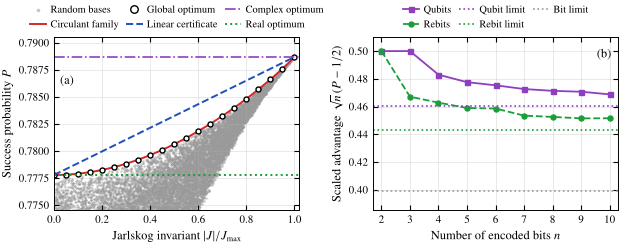

In [22]:
# Figure 4: (a) qutrit tradeoff with the Jarlskog invariant, (b) n-to-one family
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.28, 2.25), gridspec_kw={"wspace": 0.30})
# (a) qutrit tradeoff
rs = np.random.default_rng(3); Js, Ps = [], []
for _ in range(30000):
    U = unitary_group.rvs(3, random_state=rs); Js.append(abs(Jinv(U))/JM); Ps.append(0.5 + np.abs(U).sum()/18)
ax1.scatter(Js, Ps, s=3, color=GRAY, alpha=0.55, lw=0, rasterized=True, label=r"Random bases")
ax1.plot(tg/JM, Pg, color=RED, lw=1.4, label=r"Circulant family")
ax1.plot(ts/JM, env, 'o', ms=3.6, mfc='white', mec=BLACK, mew=1.0, label=r"Global optimum")
ax1.plot([0, 1], [PR3, PQ3], color=BLUE, ls='--', lw=1.4, label=r"Linear certificate")
ax1.axhline(PQ3, color=PURPLE, ls='-.', lw=1.2, label=r"Complex optimum")
ax1.axhline(PR3, color=GREEN, ls=':', lw=1.4, label=r"Real optimum")
ax1.set_xlim(0, 1.02); ax1.set_ylim(0.7745, 0.7905); ax1.grid(True)
ax1.set_xlabel(r"Jarlskog invariant $|J|/J_{\max}$"); ax1.set_ylabel(r"Success probability $P$")
ax1.text(0.025, 0.7862, r"(a)", fontsize=9)
ax1.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False,
           handlelength=1.6, handletextpad=0.4, columnspacing=0.7, borderaxespad=0.0, markerscale=1.5)
# (b) n-to-one family, scaled advantage
nn = table3[:, 0]
ax2.plot(nn, np.sqrt(nn)*(table3[:, 2] - 0.5), 's-', color=PURPLE, ms=3.6, lw=1.3, label=r"Qubits")
ax2.plot(nn, np.sqrt(nn)*(table3[:, 1] - 0.5), 'o--', color=GREEN, ms=3.6, lw=1.3, label=r"Rebits")
ax2.axhline(c[3], color=PURPLE, ls=':', lw=1.2, label=r"Qubit limit")
ax2.axhline(c[2], color=GREEN, ls=':', lw=1.2, label=r"Rebit limit")
ax2.axhline(c[1], color=GRAY, ls=':', lw=1.2, label=r"Bit limit")
ax2.set_xlabel(r"Number of encoded bits $n$"); ax2.set_ylabel(r"Scaled advantage $\sqrt{n}\,(P-1/2)$")
ax2.set_xticks(range(2, 11)); ax2.set_xlim(1.7, 10.3); ax2.set_ylim(0.385, 0.51); ax2.grid(True)
ax2.text(9.55, 0.4955, r"(b)", fontsize=9)
ax2.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False,
           handlelength=1.6, handletextpad=0.4, columnspacing=0.7, borderaxespad=0.0)
fig.savefig("figs/fig4.pdf"); plt.show()

## 14. Operational meaning: exposing complex conjugation

$\mathcal D=\min_{|\mathbf m|=1}\max_y|\mathbf n_y\cdot\mathbf m|$. The operational proposition of Section 3.3 states $\mathcal D\ge 2V/(3\sqrt3)$. We check it on random measurement triples, computing $\mathcal D$ by a fine grid of directions followed by local refinement.

In [23]:
rngo = np.random.default_rng(21)
def D_geom(N):
    th = np.arccos(1 - 2*rngo.random(20000)); ph = 2*np.pi*rngo.random(20000)
    M = np.stack([np.sin(th)*np.cos(ph), np.sin(th)*np.sin(ph), np.cos(th)], 1)
    vals = np.max(np.abs(M @ N.T), axis=1); i = np.argmin(vals)
    f = lambda a: np.max(np.abs(N @ np.array([np.sin(a[0])*np.cos(a[1]), np.sin(a[0])*np.sin(a[1]), np.cos(a[0])])))
    r = minimize(f, [th[i], ph[i]], method='Nelder-Mead', options={'xatol': 1e-10, 'fatol': 1e-12})
    return min(r.fun, vals[i])
worst = 0
for _ in range(300):
    N = rngo.normal(size=(3, 3)); N /= np.linalg.norm(N, axis=1, keepdims=True); N *= rngo.uniform(0.5, 1, (3, 1))
    worst = max(worst, abs(np.linalg.det(N)) / D_geom(N))
print("largest V/D over random triples:", worst, "  rigorous bound 3*sqrt(3)/2 =", 1.5*np.sqrt(3))
print("mutually unbiased bases: D =", D_geom(np.eye(3)), " (1/sqrt3 =", 1/np.sqrt(3), ")")

largest V/D over random triples: 2.061695988066584   rigorous bound 3*sqrt(3)/2 = 2.598076211353316
mutually unbiased bases: D = 0.5773502691916552  (1/sqrt3 = 0.5773502691896258 )


## 15. Rounds needed for certification (Table 2) and adversarial certificate for the published data

In [24]:
L = np.log(1e3)
print("eta   P_eta    iid V*=0.25  iid V*=0.5  adv V*=0.25  adv V*=0.5")
for eta in [0.95, 0.97, 0.98, 0.99, 1.0]:
    Pe = 0.5 + eta*(P_Q - 0.5); row = []
    for Vs in [0.25, 0.5]:
        gap = Pe - float(Pbound(Vs)); row.append(L/(2*gap*gap) if gap > 0 else np.inf)
    for Vs in [0.25, 0.5]:
        gap = Pe - (P_R + (P_Q - P_R)*Vs); row.append(2*L/(gap*gap) if gap > 0 else np.inf)
    print(f"{eta:.2f}  {Pe:.5f}  " + "  ".join(f"{x:.1e}" for x in row))
n_exp = 24*2.4e7
az = np.sqrt(2*L/n_exp)
print(f"published data: n = {n_exp:.2e}, Azuma correction = {az:.2e}, adversarial Vbar >= {(P_exp - az - P_R)/(P_Q - P_R):.4f}")
print(f"operational: D >= {2/(3*np.sqrt(3))*float(Vcert(P_hoef)):.4f}")

eta   P_eta    iid V*=0.25  iid V*=0.5  adv V*=0.25  adv V*=0.5
0.95  0.77424  3.5e+05  inf  inf  inf
0.97  0.78001  4.3e+04  1.4e+05  4.4e+05  2.0e+07
0.98  0.78290  2.5e+04  5.7e+04  1.9e+05  9.9e+05
0.99  0.78579  1.6e+04  3.0e+04  1.1e+05  3.2e+05
1.00  0.78868  1.1e+04  1.9e+04  6.8e+04  1.5e+05
published data: n = 5.76e+08, Azuma correction = 1.55e-04, adversarial Vbar >= 0.8761
operational: D >= 0.3571


## 16. Why symmetrization does not prove Conjecture 1

Averaging the moduli matrix $p_{ij}=|U_{ij}|^2$ over simultaneous permutations of rows and columns produces the circulant pattern and cannot decrease $\sum_{ij}\sqrt{p_{ij}}$. A proof along these lines would need $J^2$ not to increase under this averaging, equivalently $J^2(p)\ge J_c^2(\mathrm{tr}\,p/3)$ for the best transversal. The check below shows that this fails.

In [25]:
perms = list(itertools.permutations(range(3)))
def Jc2(a):
    s2 = (1 - a)/2; return s2**3*(4 - 9*s2)/4
viol = 0; worst = 0; rs2 = np.random.default_rng(0)
for _ in range(50000):
    U = unitary_group.rvs(3, random_state=rs2); p = np.abs(U)**2
    a = min(sum(p[i, pi[i]] for i in range(3)) for pi in perms)/3
    if 1/9 <= a <= 1/3:
        d = Jc2(a) - Jinv(U)**2
        if d > 0: viol += 1; worst = max(worst, d)
print("unitaries violating the symmetrization inequality:", viol, "  largest violation:", worst)

unitaries violating the symmetrization inequality: 39914   largest violation: 0.005262400259041953


## 17. Detection losses (Proposition 3)

Binning the no-click rounds with a random outcome gives $P_{\rm bin}=\eta_{\rm d} P_{\rm det}+(1-\eta_{\rm d})/2$. We check that the binned effects form a valid qubit measurement for a random lossy device, and compute the critical efficiency $\eta_{\rm crit}=(P_R-1/2)/(P_{\rm det}-1/2)$.

In [26]:
rl = np.random.default_rng(7)
def rand_pos(k):
    A = rl.normal(size=(2,2)) + 1j*rl.normal(size=(2,2)); return A@A.conj().T
Ms = [rand_pos(2) for _ in range(3)]; Ssum = sum(Ms)
w, Q = np.linalg.eigh(Ssum); Sinvh = Q@np.diag(w**-0.5)@Q.conj().T
E0, E1, Enc = [Sinvh@M@Sinvh for M in Ms]
B0, B1 = E0 + Enc/2, E1 + Enc/2
print("binned effects sum to identity:", np.allclose(B0 + B1, np.eye(2)),
      " positive:", np.linalg.eigvalsh(B0).min() >= -1e-12 and np.linalg.eigvalsh(B1).min() >= -1e-12)
for Pd, lab in [(P_Q, "ideal (P_det = P_Q)"), (P_exp, "published P_exp"), (P_hoef, "Hoeffding bound")]:
    print(f"{lab:22s} eta_crit = {(P_R - 0.5)/(Pd - 0.5):.4f}")

binned effects sum to identity: True  positive: True
ideal (P_det = P_Q)    eta_crit = 0.9342
published P_exp        eta_crit = 0.9413
Hoeffding bound        eta_crit = 0.9416
